# Analyze the TRAJ metric

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import sklearn
from itertools import combinations
import colorcet as cc

from sklearn.covariance import MinCovDet
from scipy.stats import chi2
import math

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

import os
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

mm_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()
mm_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()

hg_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()
hg_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
import scib
from scib.metrics import *
from analysis_helpers import *

In [3]:
df_full = pd.read_csv('../results/spreadsheets/metric_values_v10.csv', index_col=0)
pivoted_df = df_full.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')

runs = pd.read_csv('../results/spreadsheets/all_integrations.csv')

Using the NeurIPS BMMC data, we analyze whether changing the number of PCs significantly changes
the pseudotime computation.

In [4]:
adata = sc.read('../data/neurips_bmmc.h5ad')
adata

AnnData object with n_obs × n_vars = 90261 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train', 'dpt_pseudotime'
    var: 'feature_types', 'gene_id', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'batch_colors', 'cell_type_colors', 'dataset_id', 'genome', 'hvg', 'log1p', 'neighbors', 'organism', 'pca', 'species', 'umap'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [5]:
pseudo = pd.Series(index=adata.obs.index, dtype=float)
for b in adata.obs['batch'].unique():
    subset =  adata[adata.obs.batch == b]
    subset = subset[subset.obs['cell_type'].isin(
        ['Reticulocyte', 'Normoblast', 'Erythroblast', 'Proerythroblast', 'MK/E prog', 'HSC', 'Lymph prog',
         'Transitional B', 'B1 B IGKC-', 'Naive CD20+ B IGKC-', 'Naive CD20+ B IGKC+', 'B1 B IGKC+', 'Plasmablast IGKC+',
         'Plasmablast IGKC-', 'Plasma cell IGKC-', 'Plasma cell IGKC+', 'G/M prog', 'CD14+ Mono', 'CD16+ Mono']
    )].copy()
    subset.uns["iroot"] = np.flatnonzero(subset.obs["cell_type"] == "HSC")[0]
    sc.pp.pca(subset, n_comps=10)
    sc.pp.neighbors(subset)
    sc.tl.diffmap(subset, n_comps=10)
    sc.tl.dpt(subset)
    
    pseudo.update(subset.obs['dpt_pseudotime'])
    
adata.obs['dpt_pseudotime_10'] = pseudo

In [6]:
pseudo = pd.Series(index=adata.obs.index, dtype=float)
for b in adata.obs['batch'].unique():
    subset =  adata[adata.obs.batch == b]
    subset = subset[subset.obs['cell_type'].isin(
        ['Reticulocyte', 'Normoblast', 'Erythroblast', 'Proerythroblast', 'MK/E prog', 'HSC', 'Lymph prog',
         'Transitional B', 'B1 B IGKC-', 'Naive CD20+ B IGKC-', 'Naive CD20+ B IGKC+', 'B1 B IGKC+', 'Plasmablast IGKC+',
         'Plasmablast IGKC-', 'Plasma cell IGKC-', 'Plasma cell IGKC+', 'G/M prog', 'CD14+ Mono', 'CD16+ Mono']
    )].copy()
    subset.uns["iroot"] = np.flatnonzero(subset.obs["cell_type"] == "HSC")[0]
    sc.pp.pca(subset, n_comps=11)
    sc.pp.neighbors(subset)
    sc.tl.diffmap(subset, n_comps=10)
    sc.tl.dpt(subset)
    
    pseudo.update(subset.obs['dpt_pseudotime'])
    
adata.obs['dpt_pseudotime_11'] = pseudo

In [8]:
pseudo = pd.Series(index=adata.obs.index, dtype=float)
for b in adata.obs['batch'].unique():
    subset =  adata[adata.obs.batch == b]
    subset = subset[subset.obs['cell_type'].isin(
        ['Reticulocyte', 'Normoblast', 'Erythroblast', 'Proerythroblast', 'MK/E prog', 'HSC', 'Lymph prog',
         'Transitional B', 'B1 B IGKC-', 'Naive CD20+ B IGKC-', 'Naive CD20+ B IGKC+', 'B1 B IGKC+', 'Plasmablast IGKC+',
         'Plasmablast IGKC-', 'Plasma cell IGKC-', 'Plasma cell IGKC+', 'G/M prog', 'CD14+ Mono', 'CD16+ Mono']
    )].copy()
    subset.uns["iroot"] = np.flatnonzero(subset.obs["cell_type"] == "HSC")[0]
    sc.pp.pca(subset, n_comps=50)
    sc.pp.neighbors(subset)
    sc.tl.diffmap(subset, n_comps=15)
    sc.tl.dpt(subset, n_dcs=15)
    
    pseudo.update(subset.obs['dpt_pseudotime'])
    
adata.obs['dpt_pseudotime_50_15'] = pseudo

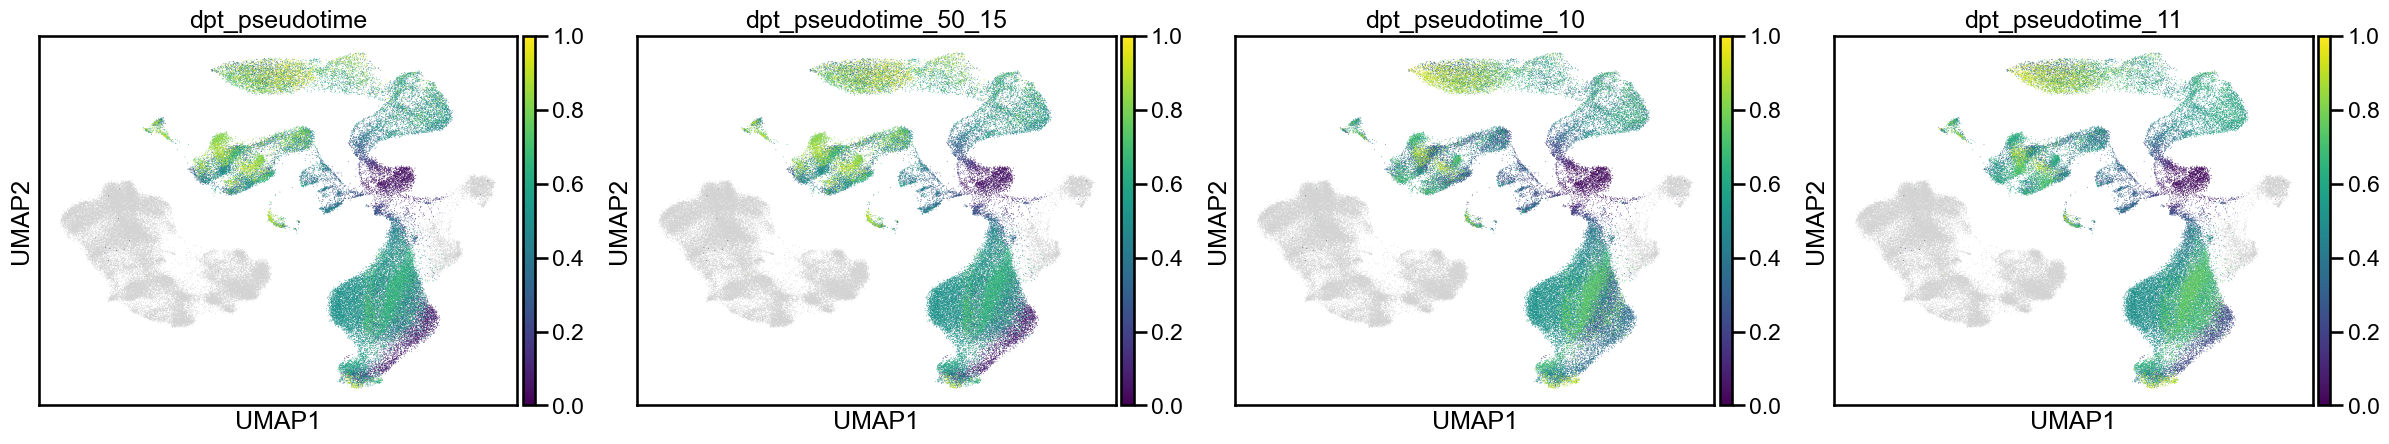

In [9]:
sc.pl.umap(adata, color=['dpt_pseudotime', 'dpt_pseudotime_50_15', 'dpt_pseudotime_10', 'dpt_pseudotime_11'])

In [10]:
adata.obs['dpt_pseudotime_10'].corr(adata.obs['dpt_pseudotime_11'], method='spearman')

np.float64(0.6699599064644254)

In [11]:
adata.obs['dpt_pseudotime'].corr(adata.obs['dpt_pseudotime_50_15'], method='spearman')

np.float64(0.999673398805142)

In [12]:
adata.obs['dpt_pseudotime'].corr(adata.obs['dpt_pseudotime_10'], method='spearman')

np.float64(0.675865217378145)

In [17]:
dirs = runs[runs.name.str.contains('neurips_bmmc')]

In [20]:
dpt_10_res = []
dpt_11_res = []

for ind, d in dirs.iterrows():
    adata_int = sc.read(f"{d['workdir']}/save_dir/adata.h5ad")
    batch_col = adata_int.obs.columns[0]
    celltype_col = adata_int.obs.columns[-11]

    if adata_int.X is None:
        adata_int = ad.AnnData(
            X=adata.X,
            obs=adata_int.obs,
            var=adata.var,
            uns=adata_int.uns,
            obsm=adata_int.obsm,
            varm=adata_int.varm,
            obsp=adata_int.obsp,
            varp=adata.varp,
            layers=adata.layers,
    )
        
    dpt_10_res.append((d['integration'], trajectory_conservation(adata, adata_int, celltype_col, pseudotime_key='dpt_pseudotime_10')))
    dpt_11_res.append((d['integration'], trajectory_conservation(adata, adata_int, celltype_col, pseudotime_key='dpt_pseudotime_11')))

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:120: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  n_components, adata_post.obs["neighborhood"] = connected_components(
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:124: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  start_clust = adata_pre.obs.groupby(ct_key)[pseudotime_key].mean().idxmin()
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis
/ubc/cs/research/beaver/projects/Single-ce

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:124: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  start_clust = adata_pre.obs.groupby(ct_key)[pseudotime_key].mean().idxmin()
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:76: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because t

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:76: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  adata_post_ti.obs["dpt_pseudotime"].fillna(0, inplace=True)
/ubc/cs/research/beaver/projects/Single-cell-integration-

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:76: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  adata_post_ti.obs["dpt_pseudotime"].fillna(0, inplace=True)
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:120: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  n_components, adata_post.obs["neighborhood"] = connected_components(
/ubc/cs/research/beaver/projects/Single-cell-integr

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:124: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  start_clust = adata_pre.obs.groupby(ct_key)[pseudotime_key].mean().idxmin()
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:76: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because t

...

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:120: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  n_components, adata_post.obs["neighborhood"] = connected_components(
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:124: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  start_clust = adata_pre.obs.groupby(ct_key)[pseudotime_key].mean().idxmin()
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis
/ubc/cs/research/beaver/projects/Single-ce

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:124: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  start_clust = adata_pre.obs.groupby(ct_key)[pseudotime_key].mean().idxmin()
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:76: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because t

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:76: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  adata_post_ti.obs["dpt_pseudotime"].fillna(0, inplace=True)
/ubc/cs/research/beaver/projects/Single-cell-integration-

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:76: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  adata_post_ti.obs["dpt_pseudotime"].fillna(0, inplace=True)
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:120: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  n_components, adata_post.obs["neighborhood"] = connected_components(
/ubc/cs/research/beaver/projects/Single-cell-integr

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:124: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  start_clust = adata_pre.obs.groupby(ct_key)[pseudotime_key].mean().idxmin()
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/scanpy/tools/_dpt.py:25: ImplicitModificationWarning: Setting element `.obsm['X_diffmap']` of view, initializing view as actual.
  adata.obsm["X_diffmap"] = dpt.eigen_basis
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/trajectory.py:76: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because t

In [26]:
dpt_10_df = pd.DataFrame(dpt_10_res, columns=['Integration', 'Value'])
dpt_11_df = pd.DataFrame(dpt_11_res, columns=['Integration', 'Value'])

In [39]:
dpt_10_df = dpt_10_df.sort_values('Integration').reset_index(drop=True)
dpt_11_df = dpt_11_df.sort_values('Integration').reset_index(drop=True)

In [32]:
dpt_default_df = df_full[(df_full.Metric == 'traj') & (df_full.Dataset == 'neurips_bmmc')]
dpt_default_df = dpt_default_df[~dpt_default_df['Value'].isna()]
dpt_default_df = dpt_default_df[['Integration', 'Value']]

In [40]:
dpt_default_df = dpt_default_df.reset_index(drop=True)

In [48]:
df_merged = dpt_10_df.merge(dpt_11_df, on='Integration', suffixes=('_10', '_11'))
df_merged = df_merged.merge(dpt_default_df, on='Integration', suffixes=('', '_default'))

In [50]:
df_merged['diff1'] = df_merged['Value_10'] - df_merged['Value_11']

In [51]:
df_merged['diff2'] = df_merged['Value_10'] - df_merged['Value']

In [52]:
df_merged

,Integration,Value_10,Value_11,Value,diff1,diff2
0,cca-1,0.663122,0.669096,0.702660,-0.005974,-0.039538
1,clear-1,0.540648,0.545228,0.559913,-0.004581,-0.019266
2,cyclone-1,0.560910,0.579531,0.659693,-0.018621,-0.098783
3,equidistant-1,0.000000,0.000000,0.000000,0.000000,0.000000
4,gedi-1,0.602165,0.646705,0.681343,-0.044541,-0.079178
5,geneformer-1,0.411311,0.429008,0.520692,-0.017697,-0.109381
6,geneptw-1,0.650069,0.613033,0.543988,0.037036,0.106081
7,harmony-1,0.683362,0.672679,0.689221,0.010683,-0.005859
8,imap-1,0.654375,0.616745,0.544265,0.037630,0.110110
9,islander-1,0.632031,0.606049,0.510835,0.025982,0.121196


In [73]:
scipy.stats.wilcoxon(df_merged['diff1'])

WilcoxonResult(statistic=np.float64(192.0), pvalue=np.float64(0.02674695290138831))

In [75]:
scipy.stats.wilcoxon(df_merged['diff2'])

WilcoxonResult(statistic=np.float64(295.0), pvalue=np.float64(0.5505061472379065))

In [ ]:
df_merged['Integration'] = df_merged['Integration'].str[:-2]

/scratch-ssd/slurm-jobs/yinian/1778040/ipykernel_3061083/3250174157.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_long['Rank'] = df_long.groupby('Metric_Level')['Score'].rank(ascending=False, method='min')
/scratch-ssd/slurm-jobs/yinian/1778040/ipykernel_3061083/3250174157.py:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['10D PCA', '11D PCA', '50D PCA'])


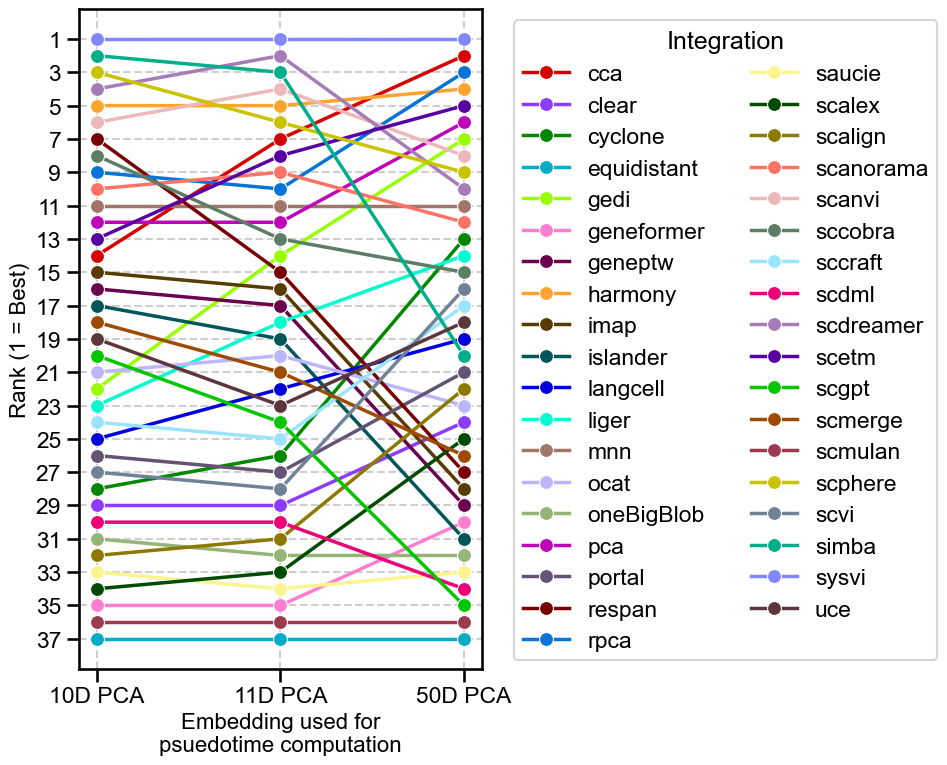

In [80]:
value_vars = ['Value_10', 'Value_11', 'Value']
df_long = df_merged.melt(
    id_vars=['Integration'], 
    value_vars=value_vars, 
    var_name='Metric_Level', 
    value_name='Score'
)

# 2. Set categorical order for the x-axis
df_long['Metric_Level'] = pd.Categorical(
    df_long['Metric_Level'], 
    categories=value_vars, 
    ordered=True
)

# 3. Calculate Ranks within each level (Descending: Higher Score = Rank 1)
df_long['Rank'] = df_long.groupby('Metric_Level')['Score'].rank(ascending=False, method='min')

# 4. Setup Plotting
plt.figure(figsize=(10, 8))

# Create a consistent color map for integrations
unique_integrations = df_long['Integration'].unique()
# Use 'tab20' or 'husl' if colorcet (cc.glasbey) is not installed
palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

# 5. Plot Bump Chart
ax = sns.lineplot(
    data=df_long, 
    x='Metric_Level', 
    y='Rank', 
    hue='Integration', 
    marker='o', 
    markersize=10,
    linewidth=2.5, 
    palette=palette
)

ax.set_xlabel('Embedding used for\npsuedotime computation', fontsize=16)
ax.set_ylabel('Rank (1 = Best)', fontsize=16)

# Invert Y-axis so Rank 1 is at the top
ax.invert_yaxis()

# Ensure Y-axis only shows integer ranks
ax.set_yticks(range(1, len(unique_integrations) + 1, 2))
ax.set_xticklabels(['10D PCA', '11D PCA', '50D PCA'])

# Add grid for readability
ax.grid(True, linestyle='--', alpha=0.6)

# Move legend outside the plot
plt.legend(title='Integration', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)

plt.tight_layout()
plt.show()

In [76]:
scipy.stats.spearmanr(df_merged['Value_10'], df_merged['Value'])

SignificanceResult(statistic=np.float64(0.6477003319108582), pvalue=np.float64(1.4680957316455209e-05))

In [77]:
scipy.stats.spearmanr(df_merged['Value_10'], df_merged['Value_11'])

SignificanceResult(statistic=np.float64(0.9596965386439069), pvalue=np.float64(7.087038215040407e-21))